# Práctica 1 — Estudio de hiperparámetros de entrenamiento en MNIST

## Objetivos

Se mantiene fija la arquitectura del ejemplo original (aplanado, capa densa de 128 neuronas ReLU y salida *softmax* de 10 clases) para estudiar de forma controlada el efecto de:

- el optimizador (`SGD`, `RMSprop` y `Adam`);
- el número de épocas (5 y 10);
- el tamaño de lote (32 y 128).

Se comparan las 12 combinaciones del diseño factorial. Para cada una se calculan exactitud, número de errores y matriz de confusión en entrenamiento y test, además del tiempo de entrenamiento. Finalmente se guarda en disco el modelo con mayor exactitud de test.

In [1]:
import gc
import itertools
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.set_printoptions(linewidth=140)
plt.style.use("seaborn-v0_8-whitegrid")
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

BASE_DIR = Path.cwd()
if BASE_DIR.name != "Practica-1" and (BASE_DIR / "Practica-1").exists():
    BASE_DIR = BASE_DIR / "Practica-1"

print(f"TensorFlow: {tf.__version__}")
print(f"Dispositivo: {tf.config.list_physical_devices()}")

TensorFlow: 2.20.0
Dispositivo: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Conjunto de datos y comprobaciones

MNIST contiene 60 000 imágenes de entrenamiento y 10 000 de test. Cada imagen representa un dígito manuscrito mediante 28 × 28 píxeles en escala de grises, y cada etiqueta es un entero entre 0 y 9.

Las comprobaciones siguientes permiten detectar inmediatamente formas, rangos o etiquetas inesperadas antes de entrenar.

Entrenamiento: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Rango original: 0 255


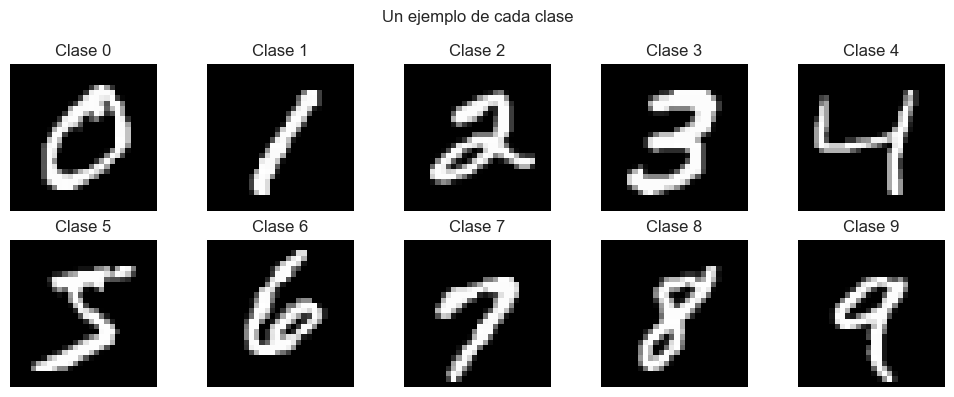

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

if x_train.shape != (60_000, 28, 28) or x_test.shape != (10_000, 28, 28):
    raise ValueError("Las dimensiones de MNIST no son las esperadas")
if not (np.isfinite(x_train).all() and np.isfinite(x_test).all()):
    raise ValueError("Las imágenes contienen valores no finitos")
if y_train.min() != 0 or y_train.max() != 9 or y_test.min() != 0 or y_test.max() != 9:
    raise ValueError("Las etiquetas deben representar las clases de 0 a 9")

print("Entrenamiento:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)
print("Rango original:", x_train.min(), x_train.max())

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train == digit)[0]
    ax.imshow(x_train[index], cmap="gray")
    ax.set_title(f"Clase {digit}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada clase")
plt.tight_layout()
plt.show()

## 2. Preprocesamiento

Los píxeles enteros de MNIST pertenecen al intervalo $[0,255]$. Se convierten a `float32` y se dividen por 255 para obtener valores en $[0,1]$. Esto mejora el condicionamiento numérico, evita gradientes innecesariamente grandes y acelera la optimización.

No se aplica ninguna transformación distinta entre configuraciones: así la comparación es justa.

In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Tipo:", x_train.dtype)
print("Rango normalizado:", x_train.min(), x_train.max())
print("Ejemplos por clase (train):", np.bincount(y_train, minlength=10))
print("Ejemplos por clase (test): ", np.bincount(y_test, minlength=10))

Tipo: float32


Rango normalizado: 0.0 1.0
Ejemplos por clase (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Ejemplos por clase (test):  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


## 3. Diseño experimental

Se utiliza un **diseño factorial completo** $3\times2\times2$: cada optimizador se prueba con ambos números de épocas y ambos tamaños de lote. Cambiar una sola dimensión del diseño permite atribuir las diferencias al parámetro estudiado, mientras que probar todas las combinaciones también revela interacciones.

Para que la comparación sea reproducible:

1. todas las configuraciones usan exactamente la misma arquitectura y los mismos datos;
2. se restablece la misma semilla antes de construir cada modelo;
3. se activa la ejecución determinista de TensorFlow;
4. no se incluye el tiempo de predicción dentro del tiempo de entrenamiento;
5. el modelo se ordena por exactitud de test, después por menor número de errores y finalmente por menor tiempo.

> **Nota metodológica:** elegir hiperparámetros mirando el test produce una estimación algo optimista. Se hace aquí porque el enunciado solicita comparar entrenamiento y test. En un proyecto real se elegiría con validación y se usaría el test una sola vez al final.

In [4]:
OPTIMIZERS = {
    "SGD": lambda: tf.keras.optimizers.SGD(),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(),
    "Adam": lambda: tf.keras.optimizers.Adam(),
}
EPOCHS_VALUES = (5, 10)
BATCH_SIZES = (32, 128)
CONFIGURATIONS = [
    {"optimizer": optimizer, "epochs": epochs, "batch_size": batch_size}
    for optimizer, epochs, batch_size in itertools.product(OPTIMIZERS, EPOCHS_VALUES, BATCH_SIZES)
]

pd.DataFrame(CONFIGURATIONS)

,optimizer,epochs,batch_size
0,SGD,5,32
1,SGD,5,128
2,SGD,10,32
3,SGD,10,128
4,RMSprop,5,32
5,RMSprop,5,128
6,RMSprop,10,32
7,RMSprop,10,128
8,Adam,5,32
9,Adam,5,128


## 4. Modelo y métricas

La pérdida es la entropía cruzada categórica dispersa, apropiada porque las etiquetas son enteros y las clases son mutuamente excluyentes. La salida *softmax* produce una distribución de probabilidad sobre los diez dígitos.

La matriz de confusión $C$ sigue la convención $C_{ij}$ = ejemplos de clase real $i$ predichos como $j$. Por tanto, su diagonal contiene los aciertos y la suma fuera de la diagonal es el número de errores.

In [5]:
def build_model(optimizer_name):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer=OPTIMIZERS[optimizer_name](),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def confusion_matrix(y_true, y_pred, n_classes=10):
    matrix = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(matrix, (y_true, y_pred), 1)
    return matrix


def evaluate_predictions(model, x, y):
    predictions = np.argmax(model.predict(x, batch_size=512, verbose=0), axis=1)
    matrix = confusion_matrix(y, predictions)
    errors = int(np.count_nonzero(predictions != y))
    accuracy = float(np.mean(predictions == y))
    if matrix.sum() != len(y) or errors != len(y) - np.trace(matrix):
        raise RuntimeError("Las métricas calculadas no son coherentes")
    return accuracy, errors, matrix

## 5. Entrenamiento de las configuraciones

Cada ejecución registra el historial por época y mide únicamente la llamada a `fit`. Los modelos se guardan temporalmente en memoria para conservar el mejor; después se liberan los demás. El fichero CSV y el archivo NumPy generados permiten revisar los resultados sin repetir el entrenamiento.

In [6]:
results = []
histories = {}
confusion_matrices = {}
best_model = None
best_key = None
best_score = (-np.inf, -np.inf, -np.inf)

for run, config in enumerate(CONFIGURATIONS, start=1):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(config["optimizer"])
    name = f'{config["optimizer"]}-e{config["epochs"]}-b{config["batch_size"]}'

    start = time.perf_counter()
    history = model.fit(
        x_train,
        y_train,
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        verbose=0,
        shuffle=True,
    )
    elapsed = time.perf_counter() - start

    train_accuracy, train_errors, train_matrix = evaluate_predictions(model, x_train, y_train)
    test_accuracy, test_errors, test_matrix = evaluate_predictions(model, x_test, y_test)
    result = {
        "configuration": name,
        **config,
        "train_accuracy": train_accuracy,
        "train_errors": train_errors,
        "test_accuracy": test_accuracy,
        "test_errors": test_errors,
        "train_seconds": elapsed,
        "accuracy_gap": train_accuracy - test_accuracy,
    }
    results.append(result)
    histories[name] = history.history
    confusion_matrices[f"{name}_train"] = train_matrix
    confusion_matrices[f"{name}_test"] = test_matrix

    score = (test_accuracy, -test_errors, -elapsed)
    if score > best_score:
        best_model = model
        best_key = name
        best_score = score

    print(
        f"[{run:02d}/{len(CONFIGURATIONS)}] {name:<18} "
        f"train={train_accuracy:.4f} test={test_accuracy:.4f} "
        f"errores_test={test_errors:>4} tiempo={elapsed:.2f}s"
    )

results_df = pd.DataFrame(results).sort_values(
    ["test_accuracy", "test_errors", "train_seconds"],
    ascending=[False, True, True],
).reset_index(drop=True)
results_df.to_csv(BASE_DIR / "resultados_configuraciones.csv", index=False)
np.savez_compressed(BASE_DIR / "matrices_confusion.npz", **confusion_matrices)

2026-09-22 17:21:11.085957: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[01/12] SGD-e5-b32         train=0.9382 test=0.9378 errores_test= 622 tiempo=3.46s


[02/12] SGD-e5-b128        train=0.9056 test=0.9107 errores_test= 893 tiempo=1.49s


2026-09-22 17:21:19.808015: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[03/12] SGD-e10-b32        train=0.9565 test=0.9516 errores_test= 484 tiempo=6.60s


[04/12] SGD-e10-b128       train=0.9217 test=0.9263 errores_test= 737 tiempo=2.74s


... (8 outputs left out)

[10/12] Adam-e5-b128       train=0.9836 test=0.9752 errores_test= 248 tiempo=1.83s


2026-09-22 17:21:56.905289: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[11/12] Adam-e10-b32       train=0.9941 test=0.9761 errores_test= 239 tiempo=8.56s


[12/12] Adam-e10-b128      train=0.9929 test=0.9776 errores_test= 224 tiempo=3.31s


## 6. Comparación numérica y gráfica

La tabla está ordenada de mejor a peor exactitud de test. La brecha `accuracy_gap = accuracy_train - accuracy_test` ayuda a interpretar la generalización: una brecha positiva grande sugiere sobreajuste; exactitudes bajas en ambos conjuntos sugieren subajuste.

El tiempo depende del equipo y de la carga del sistema, por lo que es orientativo. Las exactitudes y errores son la evidencia principal de calidad predictiva.

,configuration,optimizer,epochs,batch_size,train_accuracy,train_errors,test_accuracy,test_errors,train_seconds,accuracy_gap
0,Adam-e10-b128,Adam,10,128,99.2850%,429,97.7600%,224,3.31,1.5250%
1,RMSprop-e10-b128,RMSprop,10,128,99.1100%,534,97.6200%,238,3.14,1.4900%
2,Adam-e10-b32,Adam,10,32,99.4083%,355,97.6100%,239,8.56,1.7983%
3,RMSprop-e10-b32,RMSprop,10,32,99.2867%,428,97.5600%,244,7.97,1.7267%
4,Adam-e5-b128,Adam,5,128,98.3567%,986,97.5200%,248,1.83,0.8367%
5,RMSprop-e5-b32,RMSprop,5,32,98.5733%,856,97.5100%,249,4.14,1.0633%
6,Adam-e5-b32,Adam,5,32,98.8483%,691,97.5100%,249,4.41,1.3383%
7,RMSprop-e5-b128,RMSprop,5,128,98.2333%,1060,97.4100%,259,1.71,0.8233%
8,SGD-e10-b32,SGD,10,32,95.6533%,2608,95.1600%,484,6.60,0.4933%
9,SGD-e5-b32,SGD,5,32,93.8167%,3710,93.7800%,622,3.46,0.0367%


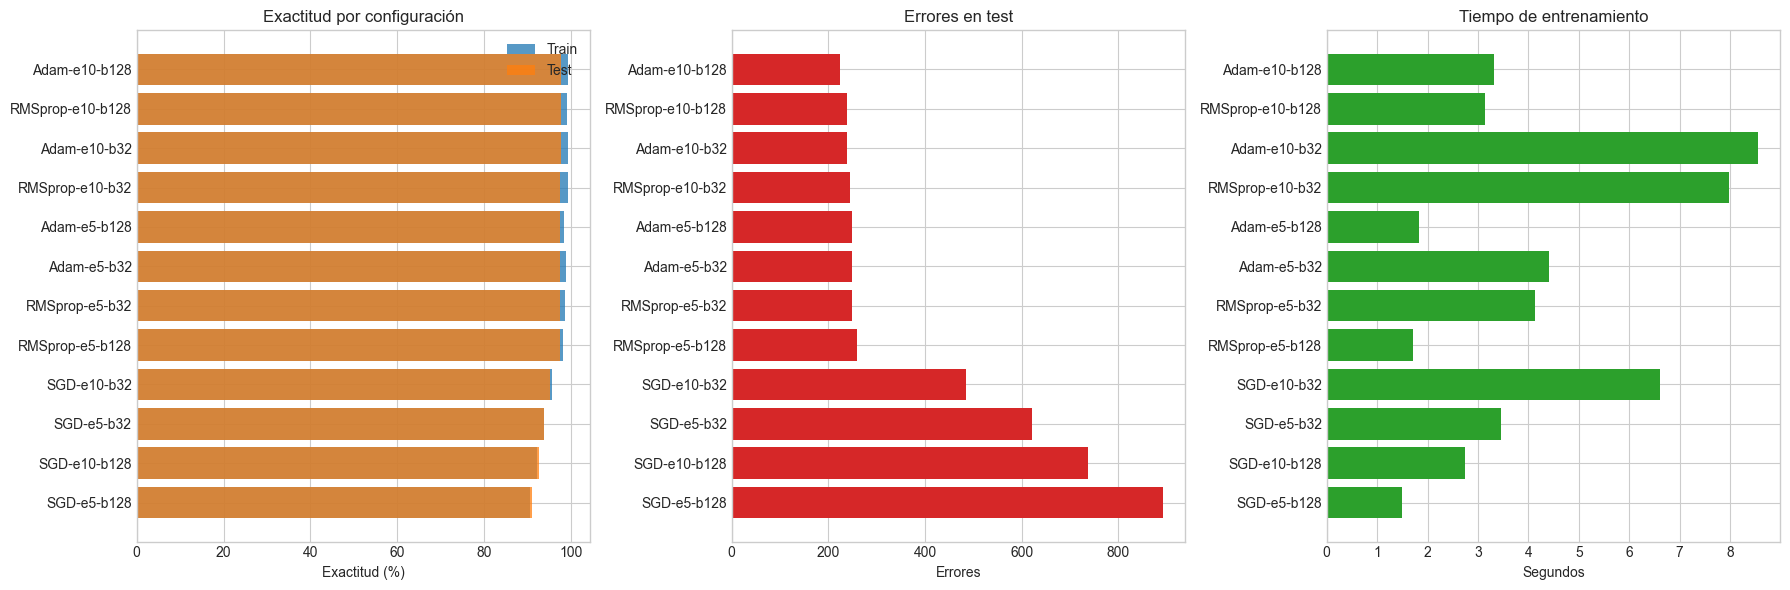

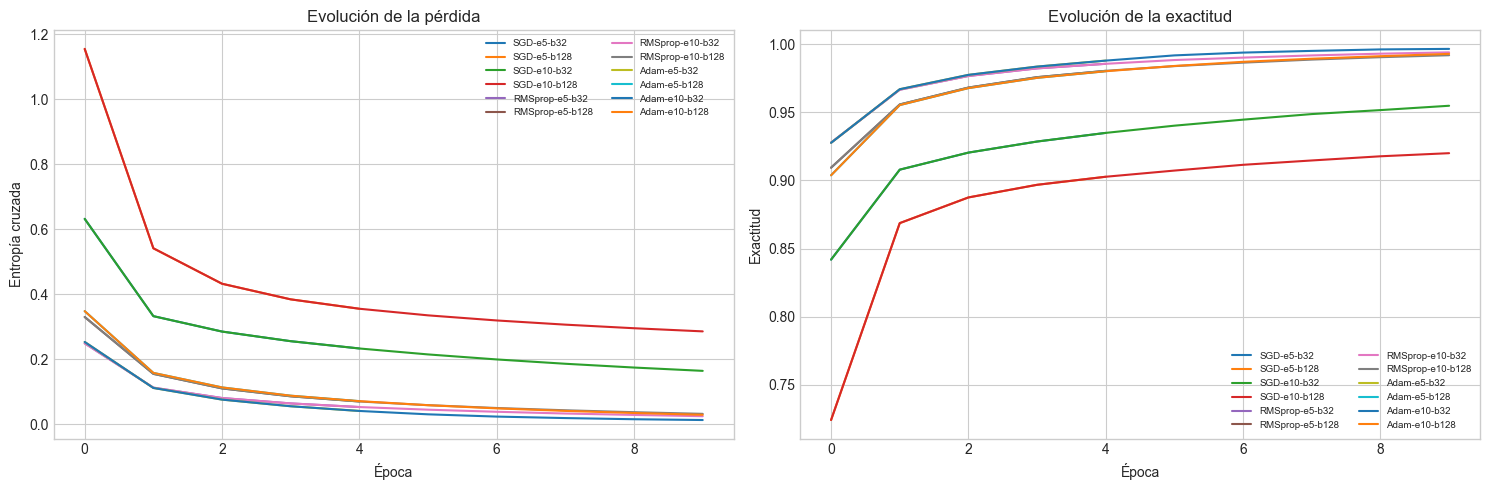

In [7]:
display_columns = [
    "configuration",
    "optimizer",
    "epochs",
    "batch_size",
    "train_accuracy",
    "train_errors",
    "test_accuracy",
    "test_errors",
    "train_seconds",
    "accuracy_gap",
]
display(results_df[display_columns].style.format({
    "train_accuracy": "{:.4%}",
    "test_accuracy": "{:.4%}",
    "train_seconds": "{:.2f}",
    "accuracy_gap": "{:.4%}",
}))

plot_df = results_df.sort_values("test_accuracy")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].barh(plot_df["configuration"], 100 * plot_df["train_accuracy"], label="Train", alpha=0.75)
axes[0].barh(plot_df["configuration"], 100 * plot_df["test_accuracy"], label="Test", alpha=0.75)
axes[0].set(xlabel="Exactitud (%)", title="Exactitud por configuración")
axes[0].legend()
axes[1].barh(plot_df["configuration"], plot_df["test_errors"], color="tab:red")
axes[1].set(xlabel="Errores", title="Errores en test")
axes[2].barh(plot_df["configuration"], plot_df["train_seconds"], color="tab:green")
axes[2].set(xlabel="Segundos", title="Tiempo de entrenamiento")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, history in histories.items():
    axes[0].plot(history["loss"], label=name)
    axes[1].plot(history["accuracy"], label=name)
axes[0].set(xlabel="Época", ylabel="Entropía cruzada", title="Evolución de la pérdida")
axes[1].set(xlabel="Época", ylabel="Exactitud", title="Evolución de la exactitud")
axes[0].legend(fontsize=7, ncol=2)
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 7. Matrices de confusión

Se muestran las matrices de **todas** las configuraciones en entrenamiento y test. La intensidad se normaliza por fila para poder comparar clases aunque no tengan exactamente el mismo número de ejemplos, mientras que cada celda conserva el recuento absoluto exigido por el enunciado.

Una diagonal intensa indica buen comportamiento. Las celdas fuera de la diagonal revelan pares de dígitos visualmente parecidos que el modelo confunde.

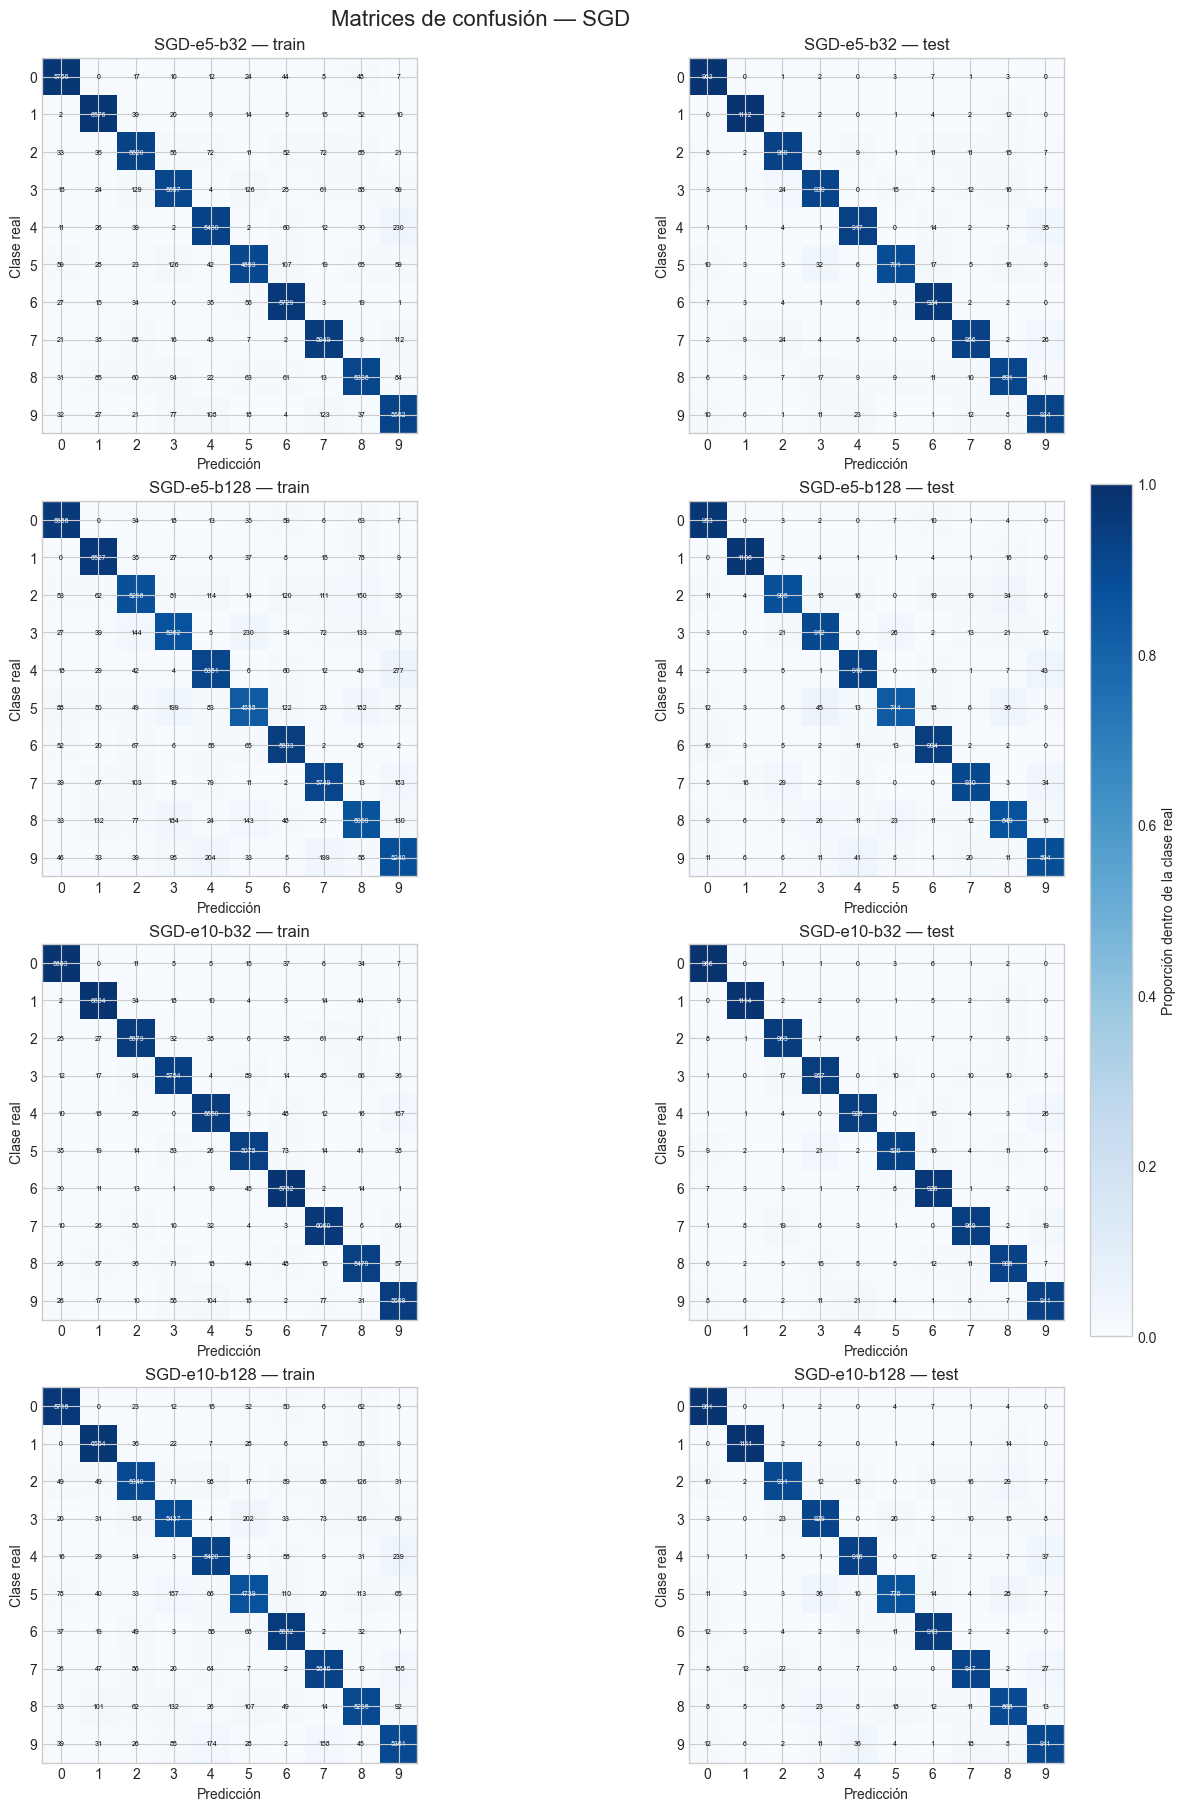

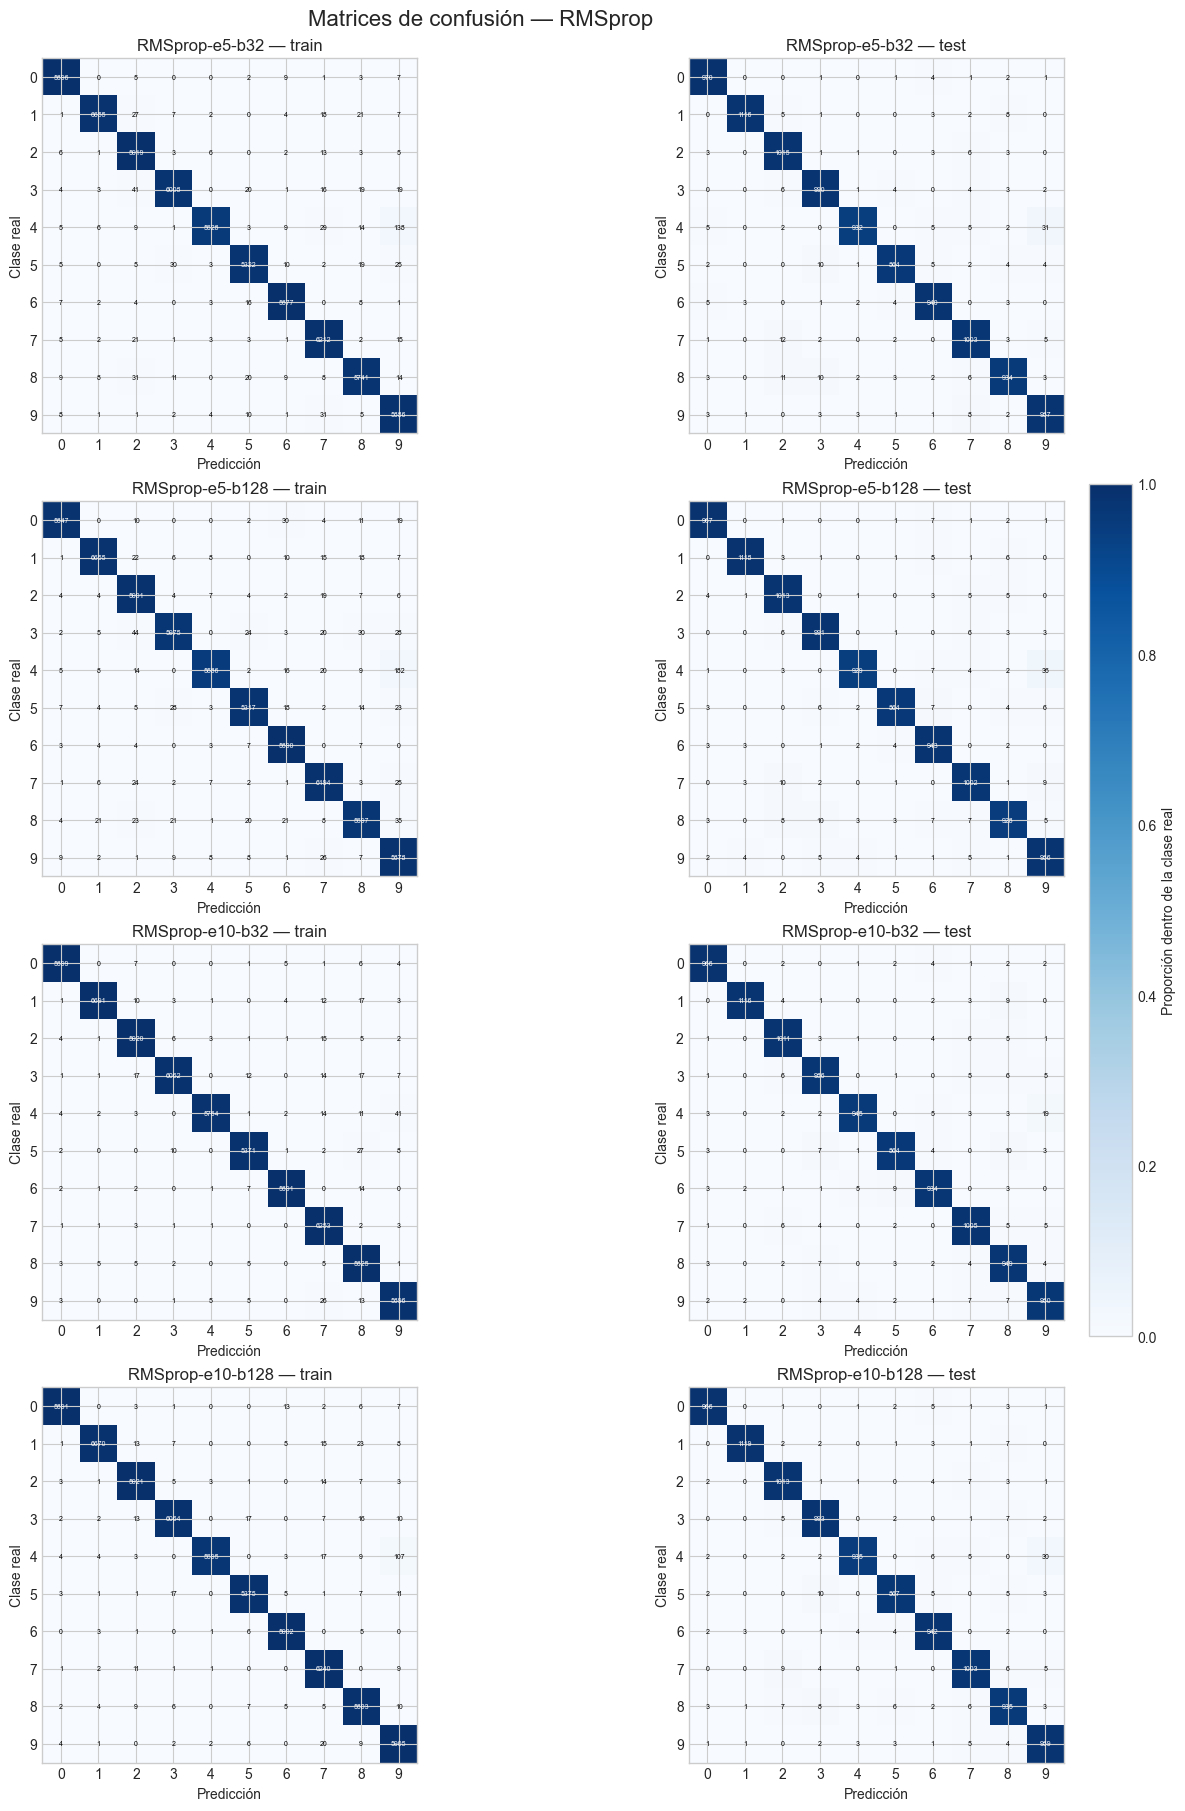

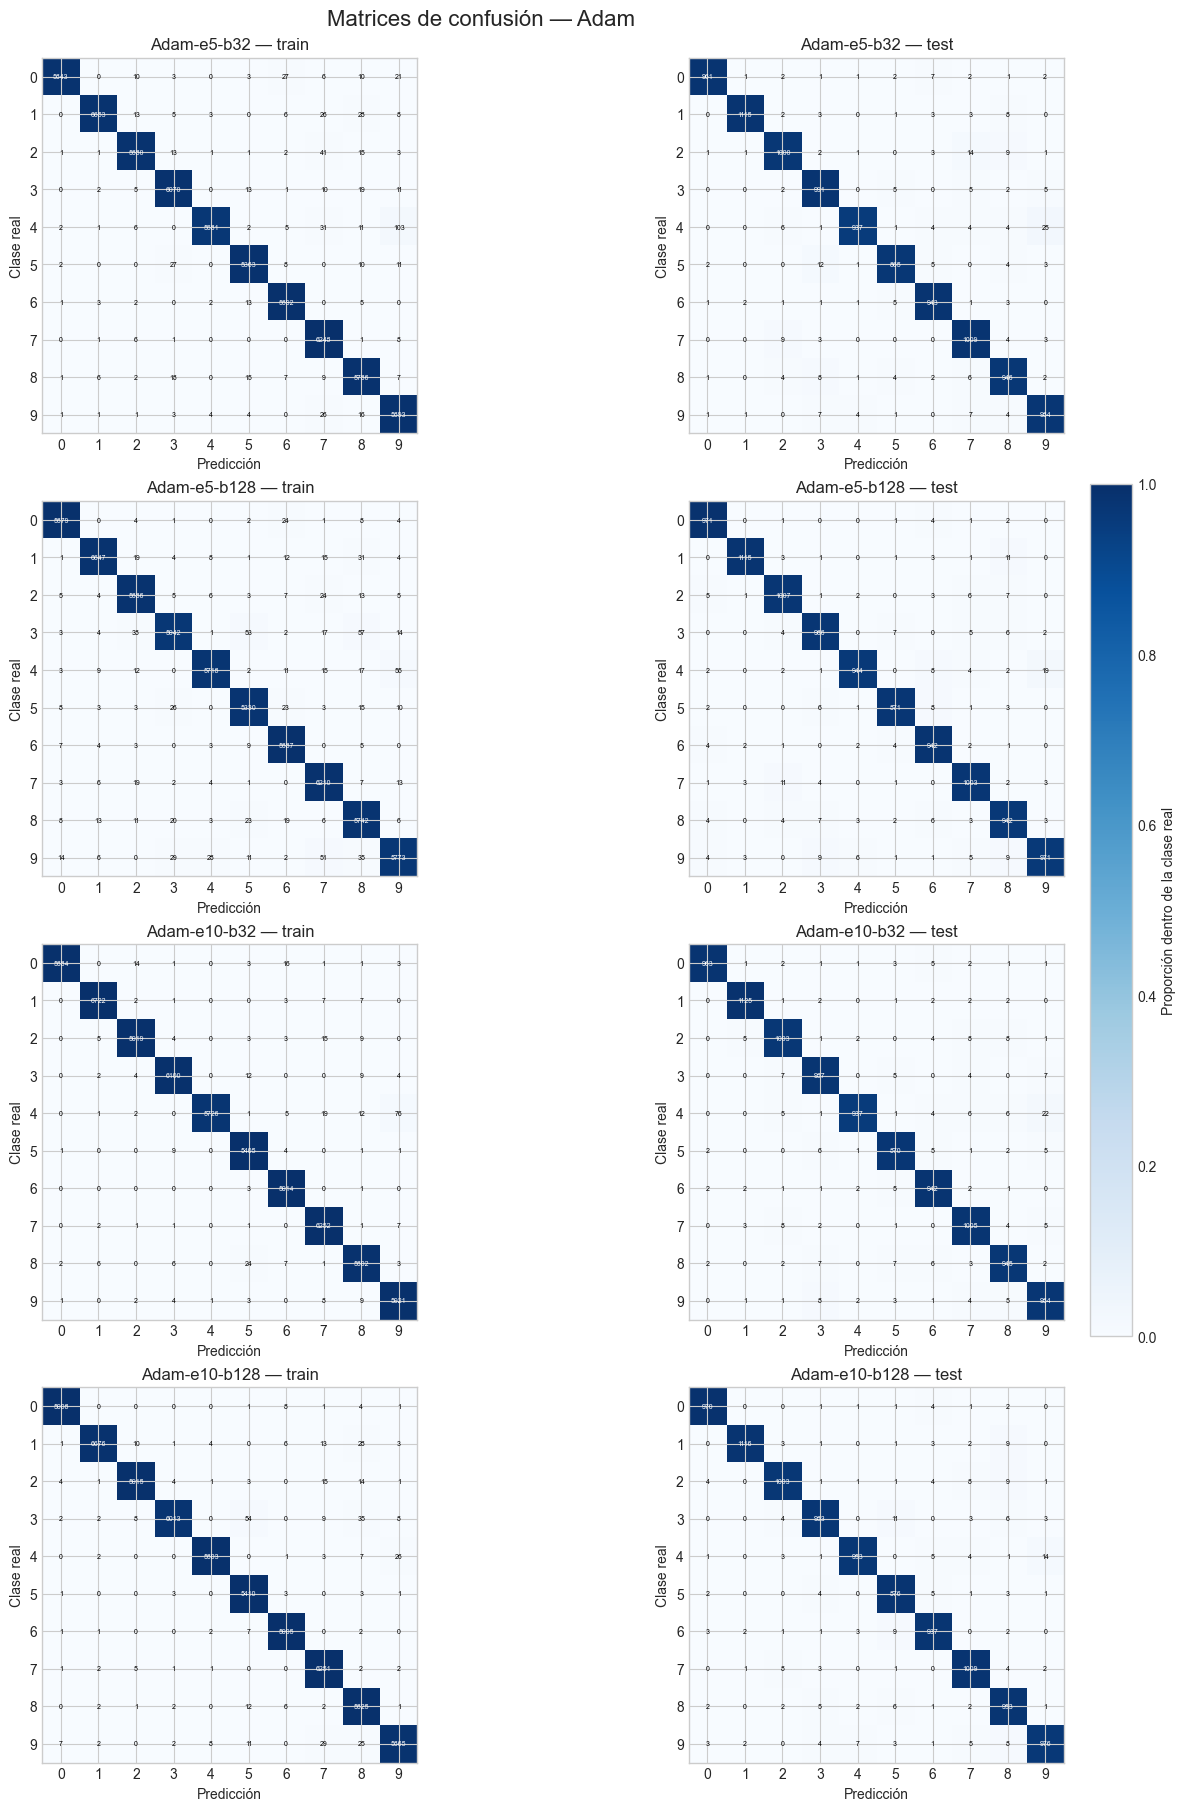

Mejor configuración: Adam-e10-b128
Accuracy train: 99.2850% (429 errores)
Accuracy test:  97.7600% (224 errores)
Tiempo:         3.31 s
Modelo guardado en: /Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/Practica-1/mejor_modelo_mnist.keras


2026-09-22 17:22:02.827182: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [8]:
def draw_confusion_matrix(ax, matrix, title):
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    ax.set(title=title, xlabel="Predicción", ylabel="Clase real", xticks=range(10), yticks=range(10))
    for row in range(10):
        for column in range(10):
            value = matrix[row, column]
            color = "white" if normalized[row, column] > 0.5 else "black"
            ax.text(column, row, value, ha="center", va="center", fontsize=5, color=color)
    return image

for optimizer in OPTIMIZERS:
    optimizer_configs = [config for config in CONFIGURATIONS if config["optimizer"] == optimizer]
    fig, axes = plt.subplots(
        len(optimizer_configs),
        2,
        figsize=(14, 4.5 * len(optimizer_configs)),
        layout="constrained",
    )
    fig.suptitle(f"Matrices de confusión — {optimizer}", fontsize=16)
    for row, config in enumerate(optimizer_configs):
        name = f'{config["optimizer"]}-e{config["epochs"]}-b{config["batch_size"]}'
        image = draw_confusion_matrix(axes[row, 0], confusion_matrices[f"{name}_train"], f"{name} — train")
        draw_confusion_matrix(axes[row, 1], confusion_matrices[f"{name}_test"], f"{name} — test")
    fig.colorbar(image, ax=axes, shrink=0.5, pad=0.02, label="Proporción dentro de la clase real")
    plt.show()

best_row = results_df.iloc[0]
model_path = BASE_DIR / "mejor_modelo_mnist.keras"
best_model.save(model_path)
reloaded_model = tf.keras.models.load_model(model_path)
reloaded_accuracy, reloaded_errors, reloaded_matrix = evaluate_predictions(reloaded_model, x_test, y_test)

if not np.isclose(reloaded_accuracy, best_row["test_accuracy"]):
    raise RuntimeError("El modelo recargado no reproduce la exactitud obtenida")

print("Mejor configuración:", best_key)
print(f"Accuracy train: {best_row['train_accuracy']:.4%} ({best_row['train_errors']} errores)")
print(f"Accuracy test:  {reloaded_accuracy:.4%} ({reloaded_errors} errores)")
print(f"Tiempo:         {best_row['train_seconds']:.2f} s")
print("Modelo guardado en:", model_path.resolve())

## 8. Interpretación y conclusiones

La mejor configuración observada es **Adam, 10 épocas y lote 128**:

- `accuracy` de entrenamiento: **99,285 %** (429 errores de 60 000);
- `accuracy` de test: **97,760 %** (224 errores de 10 000);
- tiempo de entrenamiento en CPU: **aproximadamente 3,3 s**;
- brecha train–test: **1,525 puntos porcentuales**.

Los resultados son coherentes con el funcionamiento de los hiperparámetros:

1. **Optimizador.** Adam y RMSprop superan claramente a SGD con sus tasas de aprendizaje por defecto. Ambos adaptan el tamaño del paso por parámetro; SGD converge más lentamente y queda entre 91,07 % y 95,16 % de test en el presupuesto estudiado. Esto no prueba que SGD sea siempre inferior: podría mejorar con más épocas, *momentum* o una tasa ajustada.
2. **Épocas.** Pasar de 5 a 10 épocas mejora todas las combinaciones. El beneficio es especialmente visible en SGD, que aún estaba subajustando. En Adam y RMSprop la mejora de test es menor que la mejora de entrenamiento, señal de que empieza a crecer el sobreajuste.
3. **Tamaño de lote.** El lote 32 realiza cuatro actualizaciones por cada actualización de lote 128 y suele ajustar más el entrenamiento, pero tarda más. En este experimento, lote 128 con Adam alcanza la mejor generalización y es aproximadamente 2,6 veces más rápido que Adam-10-32; más actualizaciones no garantizan mejor test.
4. **Generalización.** Adam-10-32 alcanza mayor `accuracy` de entrenamiento (99,408 %) que el ganador, pero obtiene peor test (97,610 %) y una brecha mayor (1,798 puntos). Es un ejemplo de que minimizar el error de entrenamiento no equivale a maximizar la generalización.
5. **Errores por clase.** En el mejor modelo destacan las confusiones 4→9 (14 casos), 3→5 (11), 6→5 (9) y 2→8 (9). Son razonables porque estos pares pueden compartir trazos similares en escritura manuscrita.

Por tanto, **Adam-10-128 ofrece el mejor rendimiento global** dentro del espacio probado: máxima exactitud de test, pocos errores y un tiempo menor que las alternativas de lote 32. El resultado solo justifica esta elección para esta arquitectura, estos valores y esta semilla; una conclusión más robusta exigiría varias semillas y selección mediante validación.